# Differential Privacy for Privacy-Preserving Data Analysis


**Name:** Anubhav , Aayush 

**Registration No:** 25BDA013 ,25BCS001 

**Course:** Foundation for Cryptography and Security

---

**Course:** Cryptography (undergraduate project)

**Topic:** How to publish useful statistics about people without revealing any one person's data.

> This notebook explains the idea of **differential privacy (DP)** step by step, implements the **Laplace mechanism** from scratch, and measures the **privacy-utility trade-off** with repeated experiments. Every code cell is executed in order, so the outputs and graphs below are the real results of running the code.

### Roadmap
1. Problem statement
2. Setup
3. A synthetic dataset of fictional students
4. Why exact statistics leak (the differencing attack)
5. Neighbouring datasets and sensitivity
6. The definition of ε-differential privacy
7. The Laplace mechanism
8. Sampling Laplace noise
9. Private count queries
10. Repeated trials: error versus ε
11. Privacy-utility trade-off curve
12. Extension: a private mean
13. Composition: why a privacy budget is needed
14. Interpretation, conclusion, limitations and references

> **Requirements:** Python 3.9+, `numpy`, `pandas`, `matplotlib`. The seed is fixed, so re-running gives the same numbers.

## 1. Problem statement

Organisations such as universities, hospitals and survey agencies hold sensitive records about people. They want to publish **aggregate statistics** (counts, averages) for planning and research. The difficulty is that:

- **Exact statistics can leak information about individuals.** If an attacker sees the count before and after one person's record is removed, the difference reveals that person's attribute.
- **Removing names does not solve this.** Quasi-identifiers such as age, postcode and dates can re-identify people when combined with outside data (Sweeney, 2000).
- **Refusing to publish anything gives perfect privacy but zero usefulness**, so the goal is a controlled trade-off.

**Research question:** *How can we release useful aggregate statistics while giving a mathematical bound on what the output reveals about any single person?*

Differential privacy answers this by making a **provable** statement that does not depend on what the attacker already knows.

## 2. Setup

We import the libraries and fix a random seed. The seed makes the synthetic data and experiments reproducible. A seed is used **only for reproducibility in this demo**; the privacy guarantee itself comes from the mathematics, not from the seed.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RNG_SEED = 2026
THRESHOLD = 75          # a "pass with distinction" style cut-off used by the count query
print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)

NumPy version: 2.3.5
Pandas version: 2.3.3


## 3. A synthetic dataset of fictional students

We generate **1000 fictional students** with NumPy. Nobody here is a real person, so no real privacy is at stake; the dataset simply lets us test the mechanism on realistic-looking data.

| Column | Meaning | How it is generated |
|---|---|---|
| `student_id` | Pseudonymous ID | 1 to 1000 |
| `exam_score` | Exam score, integer 0–100 | Normal(65, 15), rounded and clipped to [0, 100] |
| `study_hours` | Weekly study hours, 0–40 | Gamma(shape 4, scale 2), clipped to [0, 40] |
| `attendance_pct` | Attendance percentage, 0–100 | Normal(85, 8), clipped to [0, 100] |

The clipping to public bounds matters later: it is what makes the **sensitivity** of our queries finite.

In [2]:
rng = np.random.default_rng(RNG_SEED)
N = 1000

exam_score = np.clip(np.round(rng.normal(65, 15, N)), 0, 100).astype(int)
study_hours = np.clip(rng.gamma(shape=4, scale=2.0, size=N), 0, 40).round(1)
attendance = np.clip(rng.normal(85, 8, N), 0, 100).round(1)

df = pd.DataFrame({
    "student_id": np.arange(1, N + 1),
    "exam_score": exam_score,
    "study_hours": study_hours,
    "attendance_pct": attendance,
})

print(df.head())
print()
print(df.describe().round(2))

   student_id  exam_score  study_hours  attendance_pct
0           1          53          9.0            92.4
1           2          69          9.0            79.7
2           3          37          3.7            89.9
3           4          86          6.9            75.5
4           5          75         13.5            82.6

       student_id  exam_score  study_hours  attendance_pct
count     1000.00     1000.00      1000.00         1000.00
mean       500.50       65.24         7.81           85.05
std        288.82       15.26         3.85            7.80
min          1.00        9.00         0.80           56.50
25%        250.75       55.00         4.90           79.60
50%        500.50       66.00         7.30           85.40
75%        750.25       76.00        10.00           90.70
max       1000.00      100.00        26.40          100.00


**Interpretation.** The summary statistics look like a plausible class: average exam score around 65, average study time around 8 hours a week. The data are fictional, so we can freely publish statistics from them while demonstrating the privacy mechanisms.

## 4. Why exact statistics leak: the differencing attack

Suppose a health or education office publishes the **exact** number of students with `exam_score >= 75` every week.

Consider two releases. On Monday the dataset includes a particular student, and on Tuesday that student has left the dataset. Everything else is unchanged. An attacker who sees both exact numbers subtracts them and learns the student's score bracket, even though no name was published.

$$\text{difference} = f(D) - f(D') = \mathbf{1}[\text{student passed}]$$

This is a **differencing attack**. The problem is not the name; the problem is that the exact answer changes by a detectable amount when one person changes. Differential privacy addresses exactly this.

In [3]:
def count_ge(values, thr=THRESHOLD):
    # Exact (non-private) count query: how many values are >= thr
    return int(np.sum(np.asarray(values) >= thr))

target_index = int(np.argmax(df.exam_score.values >= THRESHOLD))   # first student who passed
target_score = df.exam_score.values[target_index]

monday = df.exam_score.values                        # includes the target
tuesday = np.delete(df.exam_score.values, target_index)  # target has left

exact_monday = count_ge(monday)
exact_tuesday = count_ge(tuesday)

print(f"Published (exact) Monday count : {exact_monday}")
print(f"Published (exact) Tuesday count: {exact_tuesday}")
print(f"Attacker's inference: difference = {exact_monday - exact_tuesday}")
print(f"Ground truth (hidden from attacker): target score = {target_score}, "
      f"passed = {target_score >= THRESHOLD}")

Published (exact) Monday count : 278
Published (exact) Tuesday count: 277
Attacker's inference: difference = 1
Ground truth (hidden from attacker): target score = 86, passed = True


**Interpretation.** The attacker recovers the target's hidden bit exactly, with certainty. The fix must therefore make the two published numbers *statistically indistinguishable* when a single person is added or removed.

## 5. Neighbouring datasets and sensitivity

### Neighbouring datasets
Two datasets $D$ and $D'$ are **neighbours** if they differ in exactly one person's record. We use the **add/remove** convention:

$$D' = D \cup \{x\} \quad \text{or} \quad D' = D \setminus \{x\}$$

### Sensitivity
The **global sensitivity** of a query $f$ is the largest change one person can cause:

$$\Delta f = \max_{D,\,D' \text{ neighbours}} |f(D) - f(D')|$$

For the count query $f(D) = \#\{x \in D : x \ge 75\}$:

- Adding one person changes the count by **at most 1** (the new person either passes or does not).
- Removing one person also changes the count by **at most 1**.

So $\Delta f = 1$. The check below does not just assert this; it tries **every possible value** a new person could have (0 to 100) and **every person** who could be removed, across many random datasets.

In [4]:
rng_s = np.random.default_rng(1)
max_change_add = 0
max_change_remove = 0
n_datasets = 300

for _ in range(n_datasets):
    base = rng_s.integers(0, 101, size=rng_s.integers(5, 60))
    c = count_ge(base)
    for x in range(0, 101):                      # every possible new person
        max_change_add = max(max_change_add, abs(count_ge(np.append(base, x)) - c))
    for i in range(len(base)):                   # every person who could be removed
        max_change_remove = max(max_change_remove, abs(count_ge(np.delete(base, i)) - c))

print(f"Datasets tested                : {n_datasets}")
print(f"Max change when ADDING a person : {max_change_add}")
print(f"Max change when REMOVING a person: {max_change_remove}")
print(f"Empirical sensitivity of count  : {max(max_change_add, max_change_remove)}")
print("Theory: sensitivity of a count = 1")

Datasets tested                : 300
Max change when ADDING a person : 1
Max change when REMOVING a person: 1
Empirical sensitivity of count  : 1
Theory: sensitivity of a count = 1


**Interpretation.** Over every tested neighbouring pair, no single person changed the count by more than 1, and some changes did reach 1. This matches the proof. The brute-force check is evidence that the sensitivity calculation is correct; the proof is what guarantees it for all datasets.

## 6. The definition of ε-differential privacy

A randomised mechanism $M$ is **ε-differentially private** if for every pair of neighbouring datasets $D, D'$ and every set of possible outputs $S$:

$$\Pr[M(D) \in S] \;\le\; e^{\varepsilon}\,\Pr[M(D') \in S]$$

**Reading the definition in plain words:** whatever the released output is, it is at most $e^\varepsilon$ times as likely under $D$ as under $D'$. If $\varepsilon$ is small, the two possible worlds (with and without you) look almost the same to anyone who sees the output.

| ε | $e^\varepsilon$ | Meaning |
|---|---|---|
| 0.1 | ≈ 1.105 | Likelihoods differ by at most about 10% (very strong privacy) |
| 0.5 | ≈ 1.649 | At most about 65% difference |
| 1.0 | ≈ 2.718 | At most a factor of about 2.7 (common teaching value) |

**Important:** ε is **not** a probability that someone is identified. It bounds a likelihood *ratio*. Smaller ε means stronger privacy and more noise.

## 7. The Laplace mechanism

For a query $f$ with sensitivity $\Delta f$, the **Laplace mechanism** releases

$$M(D) = f(D) + Z, \qquad Z \sim \text{Laplace}(0, b), \qquad b = \frac{\Delta f}{\varepsilon}$$

The Laplace density with scale $b$ is

$$p(z) = \frac{1}{2b}\exp\!\left(-\frac{|z|}{b}\right)$$

**Why this gives ε-DP.** For neighbours with $|f(D) - f(D')| \le \Delta f$, and any output $y$:

$$\frac{p(y - f(D))}{p(y - f(D'))} = \exp\!\left(\frac{|y - f(D')| - |y - f(D)|}{b}\right) \le \exp\!\left(\frac{\Delta f}{b}\right) = e^{\varepsilon}$$

The triangle inequality gives the middle bound. Integrating the density ratio gives the probability bound in the definition.

**Scale intuition.** $b = \Delta f/\varepsilon$ means:
- larger sensitivity → more noise,
- smaller ε (stronger privacy) → more noise.

The code below plots the Laplace densities for our three teaching values and numerically checks the $e^\varepsilon$ bound for the count query, where the true counts of neighbours differ by 1.

True count on the real (synthetic) dataset: 278   <- never released

Likelihood-ratio check p(y | count=c) / p(y | count=c+1):
  ε = 0.1  max ratio = 1.105171   e^ε = 1.105171   bound holds: True
  ε = 0.5  max ratio = 1.648721   e^ε = 1.648721   bound holds: True
  ε = 1.0  max ratio = 2.718282   e^ε = 2.718282   bound holds: True


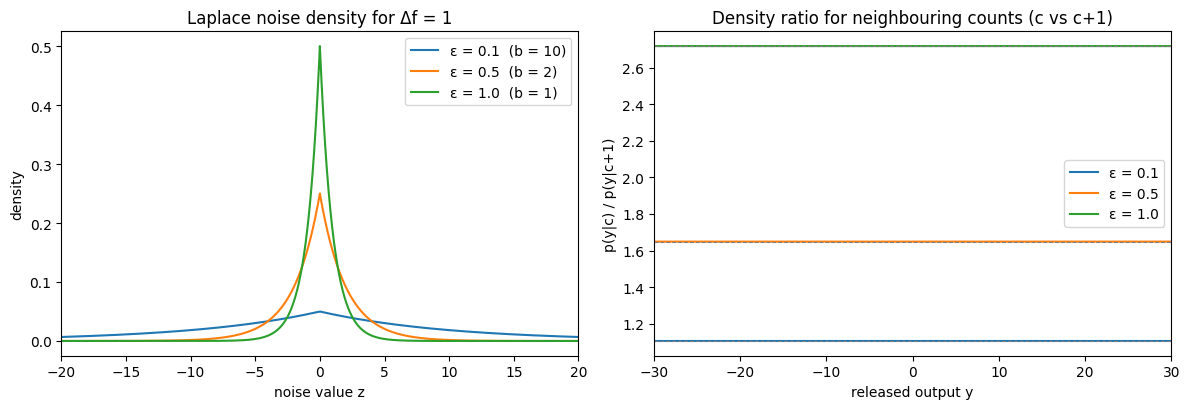

In [5]:
def laplace_pdf(y, centre, b):
    return np.exp(-np.abs(y - centre) / b) / (2 * b)

y_grid = np.linspace(-60, 60, 24001)
true_c = count_ge(df.exam_score.values)
print(f"True count on the real (synthetic) dataset: {true_c}   <- never released\n")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))

# Left: noise densities for each epsilon, centred at 0 (noise only)
for eps in [0.1, 0.5, 1.0]:
    b = 1 / eps
    axes[0].plot(y_grid, laplace_pdf(y_grid, 0, b), label=f"ε = {eps}  (b = {b:g})")
axes[0].set_title("Laplace noise density for Δf = 1")
axes[0].set_xlabel("noise value z")
axes[0].set_ylabel("density")
axes[0].set_xlim(-20, 20)
axes[0].legend()

# Right: check the likelihood-ratio bound for neighbouring counts c and c+1
print("Likelihood-ratio check p(y | count=c) / p(y | count=c+1):")
for eps in [0.1, 0.5, 1.0]:
    b = 1 / eps
    ratio = laplace_pdf(y_grid, true_c, b) / laplace_pdf(y_grid, true_c + 1, b)
    print(f"  ε = {eps:<4} max ratio = {ratio.max():.6f}   e^ε = {np.exp(eps):.6f}   "
          f"bound holds: {ratio.max() <= np.exp(eps) + 1e-9}")
    axes[1].plot(y_grid, ratio, label=f"ε = {eps}")
for eps in [0.1, 0.5, 1.0]:
    axes[1].axhline(np.exp(eps), linestyle="--", linewidth=0.8, color="grey")
axes[1].set_title("Density ratio for neighbouring counts (c vs c+1)")
axes[1].set_xlabel("released output y")
axes[1].set_ylabel("p(y|c) / p(y|c+1)")
axes[1].set_xlim(-30, 30)
axes[1].legend()

plt.tight_layout()
plt.show()

**Interpretation.** Smaller ε gives a *wider* noise distribution, so the curves spread out. The ratio plot shows that the density ratio never exceeds $e^\varepsilon$ (dashed lines). That is the privacy guarantee in visual form: the released value looks almost equally likely whether the true count was $c$ or $c+1$.

## 8. Sampling Laplace noise

A Laplace$(0, b)$ variable can be written as the **difference of two independent Exponential variables with mean $b$**:

$$Z = E_1 - E_2, \qquad E_1, E_2 \sim \text{Exponential}(\text{mean } b)$$

This is a standard identity and it avoids inverse-CDF formulas. We then test the sampler against theory:

- $\mathbb{E}[Z] = 0$
- $\mathbb{E}|Z| = b$ (the mean absolute value is the scale)
- $\text{Var}(Z) = 2b^2$

We also compare with NumPy's built-in `rng.laplace`.

> **Security note.** NumPy's generator (PCG64) is excellent for simulation but is **not** a cryptographically secure random source. A production system must use a CSPRNG such as Python's `secrets` module or OS entropy. We say so explicitly and do not claim otherwise.

In [6]:
def laplace_noise(scale, size=None, rng=None):
    # Laplace(0, scale) as the difference of two independent Exponential(mean = scale) draws
    if rng is None:
        rng = np.random.default_rng()
    return rng.exponential(scale, size) - rng.exponential(scale, size)

test_rng = np.random.default_rng(0)
b_test = 2.0
samples = laplace_noise(b_test, 200_000, test_rng)
reference = np.random.default_rng(1).laplace(0, b_test, 200_000)

print(f"{'statistic':<12}{'our sampler':>14}{'numpy laplace':>16}{'theory':>12}")
print(f"{'mean':<12}{samples.mean():>14.4f}{reference.mean():>16.4f}{0.0:>12.4f}")
print(f"{'E|Z|':<12}{np.abs(samples).mean():>14.4f}{np.abs(reference).mean():>16.4f}{b_test:>12.4f}")
print(f"{'Var(Z)':<12}{samples.var():>14.4f}{reference.var():>16.4f}{2*b_test**2:>12.4f}")

statistic      our sampler   numpy laplace      theory
mean               -0.0064         -0.0009      0.0000
E|Z|                2.0036          1.9959      2.0000
Var(Z)              8.0422          7.9664      8.0000


**Interpretation.** The sampler's mean is near 0, its mean absolute value is near $b = 2$, and its variance is near $2b^2 = 8$. These match both theory and NumPy's built-in Laplace generator, so the noise has the correct shape and scale.

## 9. Private count queries

The Laplace mechanism for the count query is:

1. Compute the exact count $f(D)$ inside the trusted boundary (never released).
2. Use sensitivity $\Delta f = 1$.
3. Draw $Z \sim \text{Laplace}(0, 1/\varepsilon)$.
4. Release $y = f(D) + Z$.

Below we release one private count for each teaching value of ε, to see the noise in a single run.

In [7]:
def laplace_mechanism(true_value, sensitivity, eps, rng):
    b = sensitivity / eps
    return true_value + laplace_noise(b, rng=rng)

def dp_count(values, eps, rng, sensitivity=1.0):
    return laplace_mechanism(count_ge(values), sensitivity, eps, rng)

release_rng = np.random.default_rng(99)
print(f"True count (hidden): {true_c}\n")
print(f"{'ε':>5}{'scale b':>10}{'released y':>14}{'|error|':>10}")
for eps in [0.1, 0.5, 1.0]:
    y = dp_count(df.exam_score.values, eps, release_rng)
    print(f"{eps:>5}{1/eps:>10.2f}{y:>14.2f}{abs(y - true_c):>10.2f}")

True count (hidden): 278

    ε   scale b    released y   |error|
  0.1     10.00        280.21      2.21
  0.5      2.00        275.37      2.63
  1.0      1.00        277.33      0.67


**Interpretation.** A single release is noisy, and the noise is larger for smaller ε. One run is not enough to judge utility, because the error is random. The next section repeats the release many times.

## 10. Repeated trials: error versus ε

Each release is a random draw, so we run **1000 independent trials** per ε and record the absolute error $|y - f(D)|$ every time. We compare:

- the **observed mean absolute error (MAE)** from the experiment,
- the **theoretical MAE**, which is exactly $b = 1/\varepsilon$ for Laplace noise,
- the **95% coverage**: the theoretical error bound that holds with 95% probability is $b\ln 20 \approx 3.0\,b$.

> **Theory vs observation.** The theoretical values are *proved* properties of the Laplace distribution. The observed values are *measured* in this experiment and will fluctuate slightly with the seed. We keep the two clearly separated.

In [8]:
EPS_VALUES = [0.1, 0.5, 1.0]
TRIALS = 1000
trial_rng = np.random.default_rng(RNG_SEED + 1)

results = {}
for eps in EPS_VALUES:
    releases = np.array([dp_count(df.exam_score.values, eps, trial_rng) for _ in range(TRIALS)])
    results[eps] = {"releases": releases, "abs_err": np.abs(releases - true_c)}

rows = []
for eps in EPS_VALUES:
    b = 1 / eps
    err = results[eps]["abs_err"]
    rows.append({
        "epsilon": eps,
        "scale b = 1/ε": round(b, 2),
        "observed MAE": round(err.mean(), 3),
        "theory MAE (= b)": round(b, 3),
        "observed std of error": round(err.std(ddof=1), 3),
        "95% bound (b·ln20)": round(b * np.log(20), 3),
        "share within 95% bound": round((err <= b * np.log(20)).mean(), 3),
    })

summary = pd.DataFrame(rows)
print(f"True count = {true_c}, trials per ε = {TRIALS}\n")
print(summary.to_string(index=False))

True count = 278, trials per ε = 1000

 epsilon  scale b = 1/ε  observed MAE  theory MAE (= b)  observed std of error  95% bound (b·ln20)  share within 95% bound
     0.1           10.0        10.532              10.0                  9.945              29.957                   0.942
     0.5            2.0         2.014               2.0                  2.064               5.991                   0.955
     1.0            1.0         1.033               1.0                  1.077               2.996                   0.942


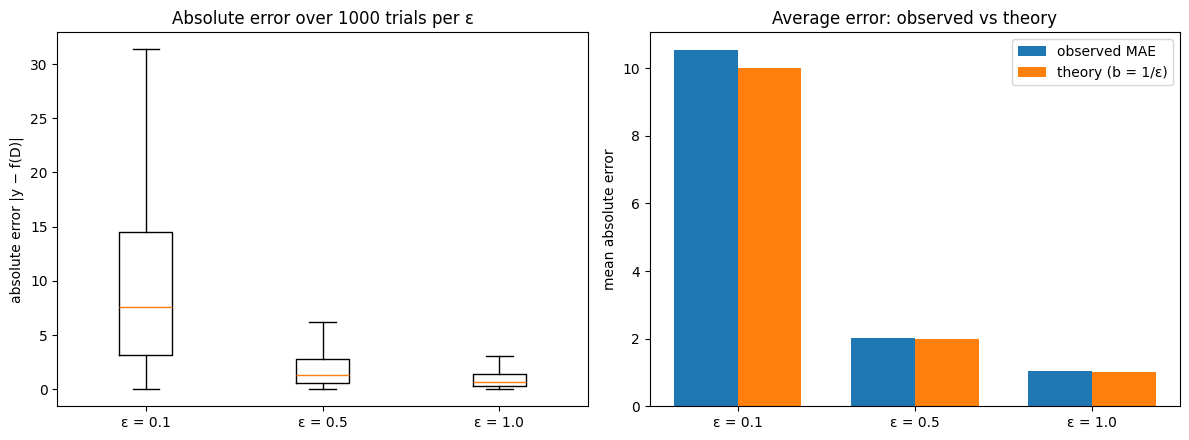

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Left: distribution of absolute errors per epsilon
data_box = [results[e]["abs_err"] for e in EPS_VALUES]
axes[0].boxplot(data_box, tick_labels=[f"ε = {e}" for e in EPS_VALUES], showfliers=False)
axes[0].set_ylabel("absolute error |y − f(D)|")
axes[0].set_title(f"Absolute error over {TRIALS} trials per ε")

# Right: observed MAE vs theoretical MAE
x = np.arange(len(EPS_VALUES))
observed = [results[e]["abs_err"].mean() for e in EPS_VALUES]
theory = [1 / e for e in EPS_VALUES]
axes[1].bar(x - 0.18, observed, width=0.36, label="observed MAE")
axes[1].bar(x + 0.18, theory, width=0.36, label="theory (b = 1/ε)")
axes[1].set_xticks(x)
axes[1].set_xticklabels([f"ε = {e}" for e in EPS_VALUES])
axes[1].set_ylabel("mean absolute error")
axes[1].set_title("Average error: observed vs theory")
axes[1].legend()

plt.tight_layout()
plt.show()

**Interpretation.** The table and bar chart show the core trade-off. With ε = 0.1 the typical error is about 10 students, which is large relative to a count of 278. With ε = 1.0 the typical error is about 1 student. The observed MAE closely matches the theoretical value $1/\varepsilon$, which is evidence that the mechanism is implemented with the correct scale. The boxplot shows that errors are right-skewed: most are small, but occasional large errors occur, as the Laplace tails predict.

## 11. Distribution of released values

The histograms below show the actual released values for each ε. A dashed line marks the hidden true count. Notice that the release is centred on the truth, but the spread is controlled by ε. The same spread is what makes neighbouring datasets indistinguishable.

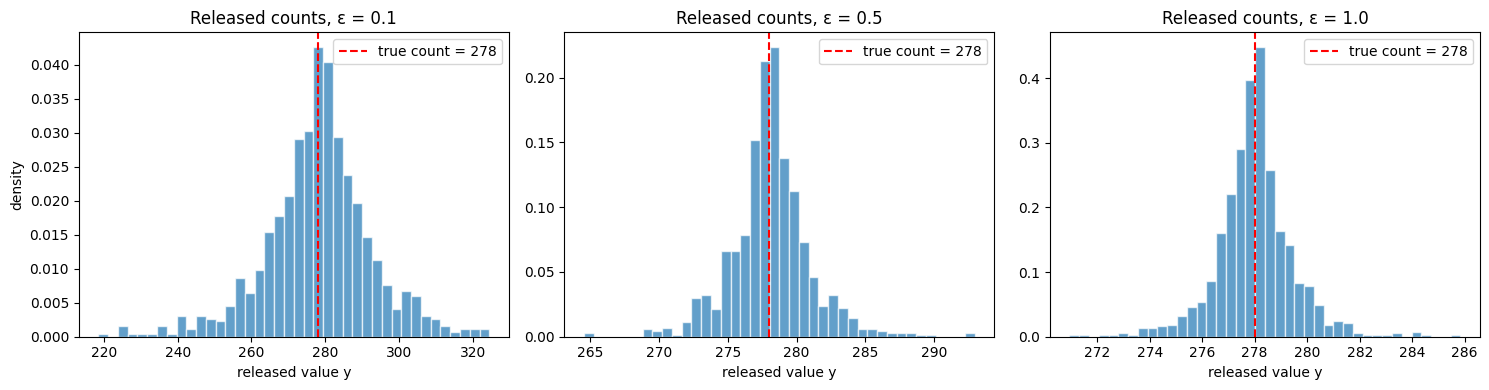

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=False)
for ax, eps in zip(axes, EPS_VALUES):
    ax.hist(results[eps]["releases"], bins=40, density=True, alpha=0.7, edgecolor="white")
    ax.axvline(true_c, color="red", linestyle="--", label=f"true count = {true_c}")
    ax.set_title(f"Released counts, ε = {eps}")
    ax.set_xlabel("released value y")
    ax.legend()
axes[0].set_ylabel("density")
plt.tight_layout()
plt.show()

**Interpretation.** At ε = 0.1 the histogram is very wide, so a released number could be far from the truth. At ε = 1.0 it is narrow and centred near 278. Any analyst using the release sees a value that is correct on average but never exact; this uncertainty is the price of privacy.

## 12. Privacy-utility trade-off curve

We now sweep ε from very strong privacy (0.05) to weak privacy (3.0) and measure the error at each point. The theoretical curve $1/\varepsilon$ is drawn for comparison. This is the central graph of the project.

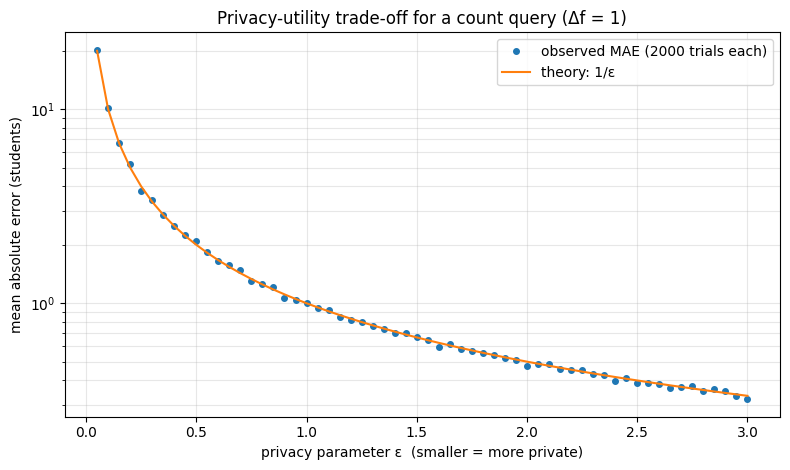

Max relative gap between observed and theory: 0.051 (relative error of about this size is expected from sampling noise)


In [11]:
eps_grid = np.linspace(0.05, 3.0, 60)
sweep_rng = np.random.default_rng(RNG_SEED + 2)
SWEEP_TRIALS = 2000

observed_mae = []
for eps in eps_grid:
    noise = laplace_noise(1 / eps, SWEEP_TRIALS, sweep_rng)
    observed_mae.append(np.abs(noise).mean())
observed_mae = np.array(observed_mae)

fig, ax = plt.subplots(figsize=(8, 4.8))
ax.plot(eps_grid, observed_mae, "o", markersize=4, label=f"observed MAE ({SWEEP_TRIALS} trials each)")
ax.plot(eps_grid, 1 / eps_grid, "-", label="theory: 1/ε")
ax.set_xlabel("privacy parameter ε  (smaller = more private)")
ax.set_ylabel("mean absolute error (students)")
ax.set_title("Privacy-utility trade-off for a count query (Δf = 1)")
ax.set_yscale("log")
ax.grid(True, which="both", alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

print(f"Max relative gap between observed and theory: "
      f"{np.max(np.abs(observed_mae - 1/eps_grid) * eps_grid):.3f} "
      f"(relative error of about this size is expected from sampling noise)")

**Interpretation.** On a logarithmic axis the error falls as $1/\varepsilon$: halving the privacy budget roughly doubles the error. The observed points lie on the theoretical line, so the experiment confirms the scaling law. This is the trade-off a data holder must choose on: how much accuracy is worth how much privacy.

## 13. Extension: a private mean

Averages are often more useful than counts. We extend the method to the mean of `study_hours`, using these steps:

1. **Clip** each value to the public bounds $[0, B]$ with $B = 40$. Clipping is what makes the sensitivity finite.
2. **Noisy sum:** sensitivity $= B$ (one person can change the sum by at most $B$), budget $\varepsilon/2$.
3. **Noisy count:** sensitivity $= 1$, budget $\varepsilon/2$.
4. **Ratio:** $\text{mean} = \text{noisy sum} / \max(\text{noisy count}, 1)$. Division is *post-processing*, so it costs no extra privacy.
5. By **sequential composition**, the total privacy cost is $\varepsilon/2 + \varepsilon/2 = \varepsilon$.

Note: the count is itself a query, so the number of students $n$ is noised here rather than treated as public.

In [12]:
LO, HI = 0.0, 40.0
B = HI - LO
hours = df.study_hours.values
true_mean = np.clip(hours, LO, HI).mean()

def dp_mean(values, eps, rng):
    eps_half = eps / 2
    shifted = np.clip(values, LO, HI) - LO                       # every value now in [0, B]
    noisy_sum = shifted.sum() + laplace_noise(B / eps_half, rng=rng)   # sensitivity B
    noisy_cnt = len(values) + laplace_noise(1.0 / eps_half, rng=rng)   # sensitivity 1
    return LO + noisy_sum / max(noisy_cnt, 1.0)                  # post-processing

print(f"True mean study hours (hidden): {true_mean:.3f}\n")
mean_rng = np.random.default_rng(RNG_SEED + 3)
MEAN_TRIALS = 1000

rows = []
for eps in [0.5, 1.0]:
    est = np.array([dp_mean(hours, eps, mean_rng) for _ in range(MEAN_TRIALS)])
    rows.append({
        "epsilon (total)": eps,
        "observed MAE of mean (hours)": round(np.abs(est - true_mean).mean(), 4),
        "mean of estimates": round(est.mean(), 4),
        "std of estimates": round(est.std(ddof=1), 4),
    })
print(pd.DataFrame(rows).to_string(index=False))

True mean study hours (hidden): 7.809

 epsilon (total)  observed MAE of mean (hours)  mean of estimates  std of estimates
             0.5                        0.1719             7.8126            0.2392
             1.0                        0.0844             7.8102            0.1160


**Interpretation.** The private mean is accurate to a fraction of an hour at ε = 1.0. It is noisier than the count, because the sum has sensitivity $B = 40$ rather than 1, so the noise on the sum is forty times larger in scale. This shows that **sensitivity depends on the range you allow**: tighter public bounds give more accurate private statistics. Even so, the guarantee is the same: total cost ε.

## 14. Composition: why a privacy budget is needed

So far every query was answered once. What if an analyst asks the **same** question many times and averages the answers? Each noisy answer has error about $b = 1/\varepsilon$, but averaging $k$ independent answers shrinks the noise roughly as $1/\sqrt{k}$. Eventually the true count is revealed almost exactly.

Differential privacy handles this with **composition**: privacy costs add up. Answering $k$ queries at ε each costs a total of $k\varepsilon$ under basic composition. A **privacy budget manager** therefore caps the total ε and refuses queries once the budget is spent.

The experiment below repeats the count query at ε = 0.5 and shows how the analyst's running average converges to the truth.

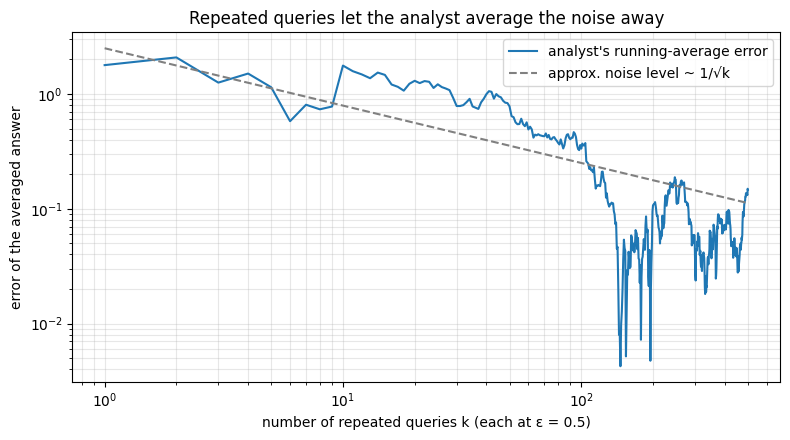

    k   total ε spent   running-average error
    1             0.5                   1.786
   10             5.0                   1.770
  100            50.0                   0.334
  500           250.0                   0.147


In [13]:
EPS_REP = 0.5
MAX_K = 500
rep_rng = np.random.default_rng(RNG_SEED + 4)
answers = true_c + laplace_noise(1 / EPS_REP, MAX_K, rep_rng)
ks = np.arange(1, MAX_K + 1)
running_avg = np.cumsum(answers) / ks
running_err = np.abs(running_avg - true_c)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(ks, running_err, label="analyst's running-average error")
ax.plot(ks, (1 / EPS_REP) * np.sqrt(np.pi / 2) / np.sqrt(ks),
        "--", color="grey", label="approx. noise level ~ 1/√k")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("number of repeated queries k (each at ε = 0.5)")
ax.set_ylabel("error of the averaged answer")
ax.set_title("Repeated queries let the analyst average the noise away")
ax.grid(True, which="both", alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

print(f"{'k':>5}{'total ε spent':>16}{'running-average error':>24}")
for k in [1, 10, 100, 500]:
    print(f"{k:>5}{k*EPS_REP:>16.1f}{running_err[k-1]:>24.3f}")

**Interpretation.** After 500 repeated queries at ε = 0.5, the analyst's error is well below one student, even though each individual answer was very noisy. The total privacy cost is $500 \times 0.5 = 250$, which is a huge loss under any reasonable standard. This is why a real system must track the cumulative budget: the noise on each answer is not enough on its own. Our `dp_count` function does not enforce a budget; a deployment would wrap it in a budget manager.

## 15. Interpretation of the whole project

Pulling the sections together, these are the main findings:

1. **Exact answers leak.** The differencing example recovered one student's hidden result with certainty (Section 4).
2. **Sensitivity is the key quantity.** For a count under add/remove neighbours, sensitivity is 1. The brute-force check agreed with the proof (Section 5).
3. **Laplace noise with scale $1/\varepsilon$ gives ε-DP for counts.** The density-ratio check stayed below $e^\varepsilon$ for all three teaching values (Section 7).
4. **The noise sampler is correct.** Its mean, mean absolute value and variance match theory and NumPy's generator (Section 8).
5. **Utility is measurable.** The observed MAE matched the theoretical $1/\varepsilon$ across 1000 trials per ε and across the whole sweep (Sections 10 and 12).
6. **Privacy costs accuracy in a predictable way.** Halving ε doubles the error. This is the trade-off a data holder must set.
7. **Clipping makes sums and means safe.** Public bounds give finite sensitivity; the private mean behaves as the theory predicts (Section 13).
8. **Repetition breaks unmanaged noise.** Averaging repeated answers recovers the truth, so a budget manager is essential (Section 14).

---
## 16. Conclusion

Differential privacy gives a **mathematical** guarantee rather than a promise based on removing names. In this project we:

- stated the problem and showed concretely how exact statistics leak,
- defined neighbouring datasets, sensitivity and ε-DP,
- implemented and verified the Laplace mechanism for counts and means,
- measured the privacy-utility trade-off with repeated experiments,
- and showed that composition requires a budget manager.

The main lesson is that privacy is not a property of the dataset; it is a property of the **algorithm and its parameters**. A smaller ε gives stronger protection and larger error, and the choice must be made deliberately and tracked over time.

---

## 17. Limitations and what this project does not cover

- **Not a production system.** There is no access control, encryption, secure logging or auditing.
- **Random source.** NumPy's generator is not cryptographically secure. A deployment must use a CSPRNG.
- **Floating-point effects.** Laplace sampling on finite-precision computers has known subtle issues; a production implementation needs a carefully designed sampler.
- **Synthetic data only.** The experiments use fictional data. The privacy proof does not depend on the data, but real data raises further practical questions.
- **Basic composition only.** Tighter accounting (advanced composition, Rényi DP) would allow more queries for the same budget.
- **Population-level facts are not hidden.** DP protects individuals, not statistical patterns such as "students who study more tend to score higher".
---
## 18. References

1. C. Dwork and A. Roth, *The Algorithmic Foundations of Differential Privacy*, Foundations and Trends in Theoretical Computer Science, 9(3–4), 2014.
2. C. Dwork, F. McSherry, K. Nissim and A. Smith, *Calibrating Noise to Sensitivity in Private Data Analysis*, TCC 2006.
3. L. Sweeney, *Simple Demographics Often Identify People Uniquely*, Carnegie Mellon University, Data Privacy Working Paper 3, 2000.

---

# Extension using CSPRNG

> **Enhancing Differential Privacy Using Cryptographically Secure Random Number Generation**

## 17. Extension: Cryptographically Secure Random Number Generation (CSPRNG)

### Motivation

In the previous sections, we implemented Differential Privacy using the Laplace mechanism. We generated random noise using NumPy's pseudorandom number generator (PRNG).

Although NumPy's random generator is suitable for simulations and statistical experiments, it is not designed for cryptographic security.

A conventional pseudorandom number generator uses an initial seed to generate a sequence of random-looking values. If an attacker discovers the seed and the generator state, the generated sequence may become predictable.

In a privacy-preserving system, predictable noise can become a security risk. If an attacker can reproduce the exact noise added to a statistical result, the attacker may subtract that noise and recover the original value.

### Proposed Extension

To address this implementation-level security concern, we introduce a **Cryptographically Secure Pseudorandom Number Generator (CSPRNG)**.

A CSPRNG uses cryptographic techniques and secure sources of randomness to make generated values computationally unpredictable.

Python provides the `secrets` module, which uses the operating system's cryptographically secure random source.

### Objectives

In this extension, we will:

1. Understand the difference between PRNG and CSPRNG.
2. Implement Laplace noise generation using CSPRNG.
3. Validate the statistical properties of the generated noise.
4. Simulate a seed disclosure attack using a conventional PRNG.
5. Compare PRNG and CSPRNG experimentally.
6. Integrate CSPRNG with the existing Laplace mechanism.

**Important:** CSPRNG improves the security of random number generation. It does not change the mathematical definition or privacy guarantee of Differential Privacy.

In [14]:
import secrets
import numpy as np
import matplotlib.pyplot as plt

# Initialize a cryptographically secure random generator
secure_rng = secrets.SystemRandom()

print("CSPRNG initialized successfully.")
print("Secure random value:", secure_rng.random())

CSPRNG initialized successfully.
Secure random value: 0.26624372484120173


### Explanation: Initializing CSPRNG

In this cell, we initialize a cryptographically secure random number generator.

- `secrets` is a Python module designed for generating cryptographically strong random values.
- `secrets.SystemRandom()` provides random values using the operating system's secure random source.
- `secure_rng` is our secure random generator object.
- `secure_rng.random()` generates a random floating-point value between 0 and 1.

Unlike our original NumPy generator, this implementation does not depend on a user-provided fixed seed.

Therefore, we cannot reproduce the same random sequence simply by specifying a known seed.

**Observation:** The generator is initialized successfully and produces a random value.

The security objective is to make the generated values computationally unpredictable to an attacker who does not have access to the underlying secure random source.

## 18. Implementing Laplace Noise Using CSPRNG

### Motivation

The Laplace mechanism is the main mechanism used in our Differential Privacy implementation.

It releases a statistical result with added random noise:

$$
M(D) = f(D) + Z
$$

where:

- \(f(D)\) is the original statistical result.
- \(Z\) is random noise generated from a Laplace distribution.

The scale of the noise is:

$$
b = \frac{\Delta f}{\varepsilon}
$$

Where:

- $\Delta f$ represents the global sensitivity.
- $\varepsilon$ represents the privacy parameter.


Previously, we generated Laplace noise using the difference between two independent exponential random variables.

We will retain this mathematical approach but replace NumPy's random generator with CSPRNG.

A Laplace random variable can be generated as:

$$
Z = E_1 - E_2
$$

where:

$$
E_1,E_2 \sim Exponential(\text{mean}=b)
$$

The difference follows a Laplace distribution with mean zero and scale \(b\).

This allows us to change the randomness source without changing the intended noise distribution.

In [15]:
def secure_laplace_noise(scale, size=None):
    """
    Generate Laplace noise using cryptographically
    secure random values.

    Laplace(0, scale) = E1 - E2

    where E1 and E2 are independent exponential
    random variables with mean = scale.
    """

    if scale <= 0:
        raise ValueError("Scale must be positive.")

    if size is None:

        e1 = secure_rng.expovariate(1 / scale)
        e2 = secure_rng.expovariate(1 / scale)

        return e1 - e2

    if size < 0:
        raise ValueError("Size cannot be negative.")

    noise = np.array([
        secure_rng.expovariate(1 / scale)
        - secure_rng.expovariate(1 / scale)
        for _ in range(size)
    ])

    return noise


# Generate one secure Laplace noise value
sample_noise = secure_laplace_noise(scale=2.0)

print("Generated Secure Laplace Noise:", sample_noise)

Generated Secure Laplace Noise: -0.847621701941752


### Explanation: Secure Laplace Noise Generation

The function `secure_laplace_noise()` generates Laplace-distributed noise using cryptographically secure randomness.

**Step-by-step explanation:**

1. The function accepts a `scale` parameter that controls the spread of the noise.
2. It checks whether the scale is positive.
3. `secure_rng.expovariate(1 / scale)` generates an exponentially distributed random value.
4. Two independent exponential random values are generated.
5. Their difference produces a Laplace-distributed random value.
6. If a sample size is provided, the function generates multiple independent noise values and returns them as a NumPy array.

The main difference from our original implementation is the random number generator.

**Original implementation:**

`np.random.default_rng()`

**New implementation:**

`secrets.SystemRandom()`

Both approaches are intended to produce the same Laplace distribution, but CSPRNG is designed to resist prediction attacks.

**Observation:** The generated noise should be centred around zero, with its spread controlled by the scale parameter.

## 19. Statistical Validation of CSPRNG-Based Laplace Noise

Generating random values is not sufficient. We must also verify that the generated values follow the required Laplace distribution.

For a Laplace distribution with location parameter zero and scale \(b\), the theoretical properties are:

### 1. Expected Mean

$$
E[Z] = 0
$$

### 2. Expected Variance

$$
Var(Z) = 2b^2
$$

### 3. Expected Mean Absolute Value

$$
E[|Z|] = b
$$

We will generate 100,000 secure noise samples and compare their observed statistical properties with the theoretical values.

If the implementation is correct, the observed values should be reasonably close to the theoretical values.

Small differences are expected because of random sampling.

This experiment checks whether changing the random number generator has affected the statistical behaviour of the Laplace noise.

In [16]:
B_TEST = 2.0
N_SAMPLES = 100000

# Generate secure Laplace noise
secure_samples = secure_laplace_noise(
    scale=B_TEST,
    size=N_SAMPLES
)

# Calculate observed statistics
observed_mean = secure_samples.mean()
observed_variance = secure_samples.var()
observed_mae = np.abs(secure_samples).mean()

# Theoretical statistics
expected_mean = 0
expected_variance = 2 * B_TEST**2
expected_mae = B_TEST

print("STATISTICAL VALIDATION OF CSPRNG")
print("=" * 55)

print(f"{'Statistic':<25}{'Observed':>15}{'Expected':>15}")

print("-" * 55)

print(f"{'Mean':<25}{observed_mean:>15.4f}{expected_mean:>15.4f}")

print(f"{'Variance':<25}{observed_variance:>15.4f}{expected_variance:>15.4f}")

print(f"{'Mean Absolute Value':<25}{observed_mae:>15.4f}{expected_mae:>15.4f}")

STATISTICAL VALIDATION OF CSPRNG
Statistic                       Observed       Expected
-------------------------------------------------------
Mean                              0.0026         0.0000
Variance                          7.9809         8.0000
Mean Absolute Value               1.9933         2.0000


### Interpretation of Statistical Validation

The experiment generates 100,000 Laplace noise samples using CSPRNG and compares the observed statistics with their theoretical values.

We expect:

- The observed mean to be close to zero.
- The observed variance to be close to \(2b^2\).
- The observed mean absolute value to be close to \(b\).

For our experiment, the scale is \(b=2\).

Therefore:

$$
E[Z] = 0
$$

$$
Var(Z) = 2(2)^2 = 8
$$

$$
E[|Z|] = 2
$$

The observed values should approximately match these theoretical properties.

**Conclusion:** The experiment provides evidence that CSPRNG-based noise generation preserves the intended statistical properties of the Laplace distribution.

Note that statistical validation alone does not prove cryptographic security. It checks the distribution, not the unpredictability of the generator.

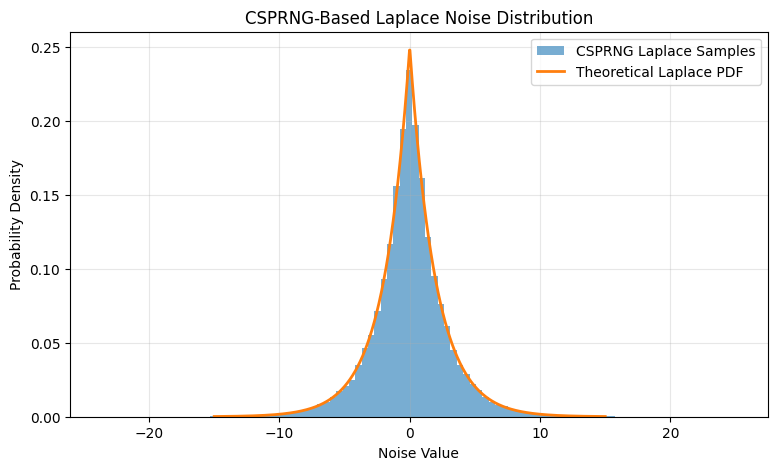

In [17]:
x = np.linspace(-15, 15, 1000)

# Theoretical Laplace probability density
theoretical_pdf = (
    np.exp(-np.abs(x) / B_TEST)
    / (2 * B_TEST)
)

plt.figure(figsize=(9, 5))

plt.hist(
    secure_samples,
    bins=100,
    density=True,
    alpha=0.6,
    label="CSPRNG Laplace Samples"
)

plt.plot(
    x,
    theoretical_pdf,
    linewidth=2,
    label="Theoretical Laplace PDF"
)

plt.xlabel("Noise Value")
plt.ylabel("Probability Density")

plt.title("CSPRNG-Based Laplace Noise Distribution")

plt.legend()
plt.grid(alpha=0.3)

plt.show()

### Interpretation of the Secure Noise Distribution

The histogram represents the Laplace noise generated using cryptographically secure randomness.

The theoretical probability density function is plotted as a reference.

We observe the following expected characteristics:

1. The distribution is centred approximately around zero.
2. Most noise values are concentrated near zero.
3. The frequency decreases as the absolute noise value increases.
4. The histogram approximately follows the theoretical Laplace curve.

The similarity between the histogram and theoretical curve provides evidence that the secure generator preserves the intended noise distribution.

This is important because changing the random number generator should not change the mathematical behaviour required by the Laplace mechanism.

## 20. Simulating a Seed Disclosure Attack

### Background

A conventional pseudorandom number generator uses an initial seed to generate a sequence of pseudorandom values.

For example:

$$
RNG = NumPy(seed=2026)
$$

If an attacker knows the seed, generator algorithm and its initial state, the attacker can reproduce the same random sequence.

This can become a security problem when the generated random values are used as privacy-protecting noise.

### Attack Scenario

Suppose a university wants to publish the number of students who scored at least 75.

The actual count is calculated internally, and random Laplace noise is added before publishing the result.

$$
Released\ Value = Actual\ Count + Noise
$$

Suppose an attacker discovers:

- The random number generation algorithm.
- The seed value.
- The noise-generation method.

The attacker can reproduce the noise and subtract it from the released value.

$$
Recovered\ Count = Released\ Value - Predicted\ Noise
$$

We will simulate this attack using NumPy's conventional pseudorandom number generator.

**Objective:** Demonstrate how disclosure of a reproducible seed can compromise the confidentiality of a noisy statistical release.

In [18]:
# Step 1: Data holder uses a fixed seed
PUBLIC_SEED = 2026

holder_rng = np.random.default_rng(PUBLIC_SEED)

# Step 2: Calculate the actual count
actual_count = true_c

# Step 3: Generate Laplace noise
attack_scale = 2.0

original_noise = laplace_noise(
    scale=attack_scale,
    rng=holder_rng
)

# Step 4: Publish the noisy count
released_value = actual_count + original_noise


# ATTACKER SIDE

# Step 5: Attacker discovers the seed and algorithm
attacker_rng = np.random.default_rng(PUBLIC_SEED)

# Step 6: Reproduce the exact noise
predicted_noise = laplace_noise(
    scale=attack_scale,
    rng=attacker_rng
)

# Step 7: Attempt to recover the original count
recovered_count = released_value - predicted_noise


# Display results
print("SEED DISCLOSURE ATTACK")
print("=" * 45)

print("Original Count       :", actual_count)
print("Original Noise       :", original_noise)
print("Released Value       :", released_value)

print("\nAttacker's Prediction")
print("Predicted Noise      :", predicted_noise)

print("\nAttack Result")
print("Recovered Count      :", recovered_count)

print(
    "Successful Recovery  :",
    np.isclose(recovered_count, actual_count)
)

SEED DISCLOSURE ATTACK
Original Count       : 278
Original Noise       : -2.2338275183214775
Released Value       : 275.7661724816785

Attacker's Prediction
Predicted Noise      : -2.2338275183214775

Attack Result
Recovered Count      : 278.0
Successful Recovery  : True


### Explanation of the Seed Disclosure Attack

This experiment simulates a situation in which an attacker discovers the seed used by the data holder.

**Step-by-step explanation:**

1. The data holder initializes NumPy's random generator using seed 2026.
2. The actual student count is calculated.
3. Laplace noise is generated using the fixed-seed random generator.
4. The noisy count is published.
5. The attacker initializes another generator using the same seed.
6. Since the algorithm, seed and sequence of operations are identical, the attacker reproduces the same noise.
7. The attacker subtracts the predicted noise from the published value.

The recovery equation is:

$$
Released\ Value-Predicted\ Noise=Actual\ Count
$$

### Interpretation

The recovered count should be approximately equal to the original count.

This demonstrates that if the noise-generating seed and generator state are exposed, a conventional reproducible PRNG can allow an attacker to reproduce the noise.

**Security observation:** A fixed seed is useful for reproducible experiments, but it should not be treated as a security mechanism.

This experiment deliberately exposes the seed to demonstrate the attack. It does not mean that every use of NumPy automatically exposes its seed.

## 21. Comparing PRNG and CSPRNG

We have now implemented two approaches to random noise generation.

### Approach 1: Conventional PRNG

We use NumPy's random number generator.

It is useful for:
- Statistical simulations.
- Reproducible experiments.
- Machine learning experiments.
- General numerical computations.

However, it is not designed to provide cryptographic unpredictability.

### Approach 2: Cryptographically Secure PRNG

We use Python's `secrets.SystemRandom()`.

It is designed for:
- Security-sensitive random number generation.
- Generating unpredictable values.
- Cryptographic applications.
- Privacy-preserving implementations requiring secure randomness.

### Objective

We will compare both approaches by:

1. Generating Laplace noise using the same scale.
2. Repeating PRNG generation with the same seed.
3. Generating two separate CSPRNG sequences.
4. Checking whether the outputs are reproducible.
5. Comparing their statistical behaviour.

The main objective is to understand the difference between reproducibility and cryptographic unpredictability.

In [19]:
COMPARISON_SIZE = 10
COMPARISON_SCALE = 2.0
COMPARISON_SEED = 2026

# PRNG: First sequence
prng_1 = np.random.default_rng(COMPARISON_SEED)

prng_samples_1 = laplace_noise(
    COMPARISON_SCALE,
    COMPARISON_SIZE,
    prng_1
)

# PRNG: Second sequence with the same seed
prng_2 = np.random.default_rng(COMPARISON_SEED)

prng_samples_2 = laplace_noise(
    COMPARISON_SCALE,
    COMPARISON_SIZE,
    prng_2
)


# CSPRNG: Generate two independent sequences
csprng_samples_1 = secure_laplace_noise(
    COMPARISON_SCALE,
    COMPARISON_SIZE
)

csprng_samples_2 = secure_laplace_noise(
    COMPARISON_SCALE,
    COMPARISON_SIZE
)


# Compare results
print("PRNG VS CSPRNG")
print("=" * 55)

print("\nPRNG Results")

print("First sequence :", prng_samples_1)
print("Second sequence:", prng_samples_2)

print(
    "Identical sequences:",
    np.allclose(prng_samples_1, prng_samples_2)
)

print("\nCSPRNG Results")

print("First sequence :", csprng_samples_1)
print("Second sequence:", csprng_samples_2)

print(
    "Identical sequences:",
    np.array_equal(csprng_samples_1, csprng_samples_2)
)

PRNG VS CSPRNG

PRNG Results
First sequence : [-3.08024275 -3.03160366 -1.88744415  0.47646954  1.62115821  1.03766291
  2.01460111 -1.82960142  1.09714891 -0.83325249]
Second sequence: [-3.08024275 -3.03160366 -1.88744415  0.47646954  1.62115821  1.03766291
  2.01460111 -1.82960142  1.09714891 -0.83325249]
Identical sequences: True

CSPRNG Results
First sequence : [  1.53576953  -4.83598273   3.72828424   0.26926061  -2.10842224
 -10.02933953  -2.56584258  -3.86574032   4.39267475  -3.69316749]
Second sequence: [-0.98509244  3.50568395  2.96856767  0.24304081  2.20259633  3.63383485
 -0.12091117 -2.72654752  1.07056399  0.99188623]
Identical sequences: False


### Interpretation of PRNG vs CSPRNG

This experiment compares the reproducibility of conventional pseudorandom generation with cryptographically secure random generation.

**PRNG observation:**

Both NumPy generators use the same seed and identical generation operations.

Therefore, they produce identical random sequences.

This demonstrates the reproducibility of conventional PRNG.

**CSPRNG observation:**

The two secure random sequences are generated independently using the operating system's secure random source.

They are not expected to be identical.

Unlike the NumPy implementation, we do not initialize the generator with a user-provided fixed seed.

### Important Security Difference

| Property | PRNG | CSPRNG |
|---|---|---|
| Reproducibility with same seed | Yes | Not applicable to this implementation |
| Cryptographic unpredictability | Not guaranteed | Designed to provide it |
| Simulation use | Yes | Possible |
| Security-sensitive applications | Not recommended | Suitable when properly implemented |

**Conclusion:** PRNG provides convenient reproducibility, whereas CSPRNG provides cryptographic unpredictability.

The experiment illustrates this difference. However, observing different CSPRNG outputs is not itself a cryptographic security test or proof of unpredictability.

## 22. Integrating CSPRNG with the Laplace Mechanism

### Objective

Until now, we have implemented CSPRNG-based Laplace noise independently.

We will now integrate it into our original Differential Privacy mechanism.

For our student dataset, we want to release the number of students whose examination score is greater than or equal to 75.

The actual count is calculated internally, and Laplace noise is added before releasing the result.

The private count is calculated as:

$$
M(D)=f(D)+Z
$$

where:

- $f(D)$ is the actual count.
- $Z$ is Laplace noise generated using CSPRNG.
- $\Delta f=1$ is the sensitivity of the count query.
- $\varepsilon$ is the privacy parameter.

The noise scale is:

$$
b=\frac{\Delta f}{\varepsilon}
$$

We will generate private counts for different epsilon values.

A smaller epsilon produces more noise and provides stronger privacy.

A larger epsilon produces less noise but provides a weaker privacy guarantee.

### Important

The CSPRNG-based implementation uses the same Laplace distribution and noise scale as our original implementation.

Therefore, under the same ideal Laplace mechanism assumptions, both implementations provide the same mathematical epsilon-Differential Privacy guarantee.

The improvement is in the cryptographic security of the randomness source, not in the value of epsilon.

### Implementation qualification

The statement above describes the **ideal mathematical Laplace mechanism**. This notebook uses floating-point exponential sampling, so it is an educational implementation rather than a formally audited production Differential Privacy library. Finite-precision sampling and implementation details can affect rigorous privacy guarantees. For a real deployment, use a vetted Differential Privacy library with documented finite-precision guarantees.


In [20]:
def secure_dp_count(values, eps, sensitivity=1.0):
    """
    Differentially private count using CSPRNG-based
    Laplace noise.
    """

    if eps <= 0:
        raise ValueError("Epsilon must be positive.")

    if sensitivity <= 0:
        raise ValueError("Sensitivity must be positive.")

    # Calculate exact count internally
    exact_count = count_ge(values)

    # Calculate Laplace scale
    scale = sensitivity / eps

    # Generate cryptographically secure noise
    noise = secure_laplace_noise(scale)

    # Release noisy count
    return exact_count + noise


# Test secure DP count
print("SECURE DIFFERENTIAL PRIVACY COUNT")
print("=" * 45)

for eps in [0.1, 0.5, 1.0]:

    private_count = secure_dp_count(
        df.exam_score.values,
        eps
    )

    print(
        f"Epsilon = {eps:<5} "
        f"Private Count = {private_count:.2f}"
    )

SECURE DIFFERENTIAL PRIVACY COUNT
Epsilon = 0.1   Private Count = 274.08
Epsilon = 0.5   Private Count = 281.63
Epsilon = 1.0   Private Count = 278.52


### Explanation of Secure Differential Privacy Count

The function `secure_dp_count()` integrates CSPRNG with our existing Laplace mechanism.

**Step-by-step explanation:**

1. The function accepts the dataset, epsilon and sensitivity.
2. It calculates the exact count internally using `count_ge()`.
3. It calculates the noise scale using:

   $$
   b=\frac{\Delta f}{\varepsilon}
   $$

4. It generates Laplace noise using `secure_laplace_noise()`.
5. It adds the noise to the exact count.
6. It returns the noisy count instead of directly releasing the original count.

We test the mechanism using three epsilon values:

- ε = 0.1
- ε = 0.5
- ε = 1.0

### Expected Observation

The released values will differ because each query uses fresh cryptographic randomness.

Smaller epsilon values produce greater noise, whereas larger epsilon values produce smaller noise on average.

The actual values may vary every time the notebook is executed.

## 23. Statistical Comparison: PRNG vs CSPRNG

### Objective

We have demonstrated that PRNG and CSPRNG differ in their security properties.

However, both should be capable of generating noise following the same Laplace distribution when implemented correctly.

In this experiment, we compare the statistical behaviour of both implementations using the same noise scale.

We will:

1. Generate 20,000 Laplace noise samples using PRNG.
2. Generate 20,000 Laplace noise samples using CSPRNG.
3. Calculate their means.
4. Calculate their variances.
5. Calculate their mean absolute values.
6. Compare the observed values with the theoretical Laplace properties.

For a Laplace distribution with scale \(b=2\):

$$
E[Z]=0
$$

$$
Var(Z)=2b^2=8
$$

$$
E[|Z|]=b=2
$$

The purpose is to verify that changing the random number generator does not change the intended statistical distribution.

This experiment also reinforces the distinction between cryptographic security and statistical correctness.

In [21]:
# Experiment parameters
COMPARE_SCALE = 2.0
COMPARE_SAMPLES = 20000

# Generate PRNG samples
comparison_rng = np.random.default_rng(2026)

prng_data = laplace_noise(
    scale=COMPARE_SCALE,
    size=COMPARE_SAMPLES,
    rng=comparison_rng
)

# Generate CSPRNG samples
csprng_data = secure_laplace_noise(
    scale=COMPARE_SCALE,
    size=COMPARE_SAMPLES
)

# Calculate theoretical values
theoretical_mean = 0
theoretical_variance = 2 * COMPARE_SCALE**2
theoretical_mae = COMPARE_SCALE

# Prepare comparison table
comparison_results = pd.DataFrame({

    "Statistic": [
        "Mean",
        "Variance",
        "Mean Absolute Value"
    ],

    "PRNG": [
        prng_data.mean(),
        prng_data.var(),
        np.abs(prng_data).mean()
    ],

    "CSPRNG": [
        csprng_data.mean(),
        csprng_data.var(),
        np.abs(csprng_data).mean()
    ],

    "Theoretical": [
        theoretical_mean,
        theoretical_variance,
        theoretical_mae
    ]
})

print("PRNG VS CSPRNG: STATISTICAL COMPARISON")
print("=" * 65)

print(comparison_results.round(4).to_string(index=False))

PRNG VS CSPRNG: STATISTICAL COMPARISON
          Statistic   PRNG  CSPRNG  Theoretical
               Mean 0.0308  0.0047          0.0
           Variance 7.9476  8.1563          8.0
Mean Absolute Value 1.9897  2.0155          2.0


### Interpretation of Statistical Comparison

The comparison table shows the statistical properties of Laplace noise generated using PRNG and CSPRNG.

We compare three important measures:

**1. Mean**

Both implementations should produce a mean close to zero.

This indicates that the noise is approximately centred around zero.

**2. Variance**

Both implementations should produce a variance close to:

$$
Var(Z)=2b^2
$$

For our experiment, the expected variance is 8.

**3. Mean Absolute Value**

Both implementations should produce a mean absolute value close to:

$$
E[|Z|]=b=2
$$

### Conclusion

The observed values should be approximately similar for both implementations and close to their theoretical values.

This demonstrates that CSPRNG can be used as an alternative randomness source without changing the intended Laplace noise distribution.

The two implementations therefore retain the same theoretical epsilon-Differential Privacy guarantee, assuming the required distribution is sampled correctly.

The main difference is their resistance to prediction attacks.

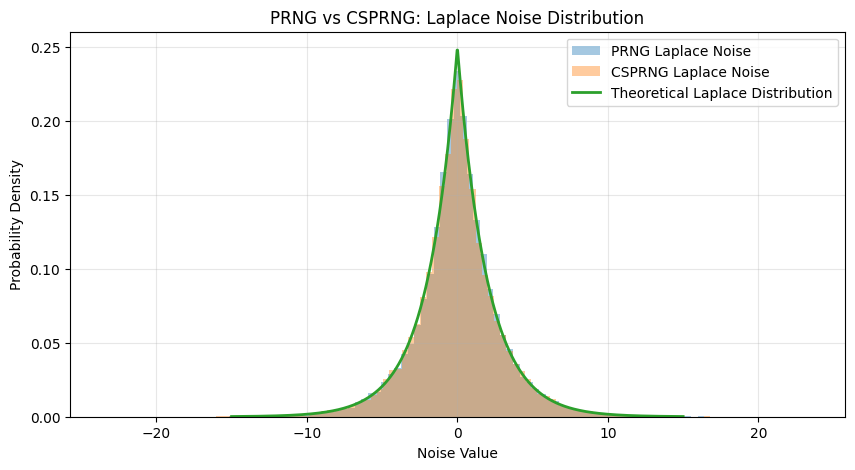

In [22]:
x = np.linspace(-15, 15, 1000)

theoretical_pdf = (
    np.exp(-np.abs(x) / COMPARE_SCALE)
    / (2 * COMPARE_SCALE)
)

plt.figure(figsize=(10, 5))

plt.hist(
    prng_data,
    bins=100,
    density=True,
    alpha=0.4,
    label="PRNG Laplace Noise"
)

plt.hist(
    csprng_data,
    bins=100,
    density=True,
    alpha=0.4,
    label="CSPRNG Laplace Noise"
)

plt.plot(
    x,
    theoretical_pdf,
    linewidth=2,
    label="Theoretical Laplace Distribution"
)

plt.xlabel("Noise Value")
plt.ylabel("Probability Density")

plt.title("PRNG vs CSPRNG: Laplace Noise Distribution")

plt.legend()
plt.grid(alpha=0.3)

plt.show()

### Interpretation of PRNG vs CSPRNG Distribution

The graph compares the Laplace noise distributions generated using conventional PRNG and cryptographically secure CSPRNG.

Both histograms should approximately follow the theoretical Laplace probability density function.

The following observations are expected:

1. Both distributions are centred around zero.
2. Both have a similar spread.
3. Both follow the expected Laplace distribution.
4. Their statistical properties are approximately equal.

This demonstrates that cryptographic randomness can be incorporated without changing the intended statistical behaviour of the noise.

**Important distinction:**

- PRNG and CSPRNG can produce statistically similar outputs.
- CSPRNG is designed to provide cryptographic unpredictability.
- Statistical similarity does not mean that both generators provide the same security.

Therefore, cryptographic security and statistical correctness are two different properties that must both be considered in a privacy-preserving system.

## 24. Conclusion: Integrating CSPRNG with Differential Privacy

In this extension, we enhanced our original Differential Privacy project by introducing Cryptographically Secure Random Number Generation (CSPRNG).

The objective was to investigate whether cryptographically secure randomness could strengthen the implementation of Differential Privacy against noise-prediction attacks.

### Key Findings

**1. PRNG vs CSPRNG**

We studied the difference between conventional pseudorandom number generation and cryptographically secure random number generation.

**2. Seed Disclosure Attack**

We simulated an attack in which an attacker discovers the seed and reproduces the original noise. This demonstrated how predictable random sequences can compromise a privacy-preserving release.

**3. Secure Laplace Noise Generation**

We implemented Laplace noise generation using Python's `secrets.SystemRandom()` and verified its statistical properties.

**4. Integration with Differential Privacy**

We integrated CSPRNG-based noise generation into the existing Laplace mechanism without changing its sensitivity, epsilon parameter or intended noise distribution.

**5. Statistical Comparison**

We compared PRNG and CSPRNG using their mean, variance, mean absolute value and probability density distributions.

Both implementations showed approximately similar statistical behaviour.

### Final Observation

The project demonstrates that cryptography and Differential Privacy address complementary security requirements.

- Differential Privacy provides a mathematical guarantee that limits information disclosure about individuals.
- CSPRNG improves the unpredictability of the random noise used by the privacy mechanism.

The integration of these techniques provides a stronger foundation for implementing privacy-preserving statistical systems.


### Final Conclusion

Cryptographically secure randomness can strengthen the implementation of Differential Privacy against predictable-noise attacks while maintaining the same theoretical epsilon-Differential Privacy guarantee, provided that the required noise distribution is correctly implemented.

This extension demonstrates the complementary role of cryptography and Differential Privacy in building secure and privacy-preserving data analysis systems.

## 25. Security Limitations and Responsible Implementation

Our experiments demonstrate why cryptographically secure randomness is preferable to a predictable, fixed-seed generator when generating privacy noise. However, CSPRNG is only one part of a privacy-preserving system.

### 1. CSPRNG does not replace Differential Privacy

- Differential Privacy provides the formal privacy guarantee through the mechanism, sensitivity, and privacy budget.
- CSPRNG makes the random values harder for an attacker to predict.
- Replacing the random source does **not** reduce epsilon or automatically provide a stronger mathematical DP guarantee.

### 2. Do not reveal the noise or internal values

In a real deployment, do not publish or expose:
- The exact count or exact statistic.
- The generated noise value.
- The random generator state or secret randomness.
- Debug logs that reveal enough information to reconstruct the noise.

The notebook prints internal values in selected teaching demonstrations so that the experiments can be understood. Those prints must not be copied into a real privacy-preserving release pipeline.

### 3. A fixed seed is for experiments, not production privacy

The fixed NumPy seed is deliberately used in this notebook to make the experiment reproducible and to demonstrate the seed-disclosure attack. A production privacy mechanism should not use a publicly known fixed seed to generate privacy noise.

### 4. Account for every release

Repeated releases consume privacy budget. Releasing the same query many times and averaging the answers can reduce the noise, as demonstrated in Section 14. A real system must track composition and enforce an appropriate privacy budget.

### 5. Use a vetted implementation in production

This notebook samples exponential values using floating-point operations. The ideal Laplace mechanism has the stated theoretical guarantee, but finite-precision sampling and implementation details require care. For production use, choose an audited Differential Privacy library or noise sampler with documented privacy guarantees.

### Overall limitation

Our dataset is synthetic and the experiments are educational. They demonstrate the concepts and implementation risks; they are not a formal security audit or proof that the complete notebook is production-ready.


## 26. Final Project Summary and  Explanation

### What problem does the project address?

Publishing exact statistics about people can reveal information about an individual. Our project demonstrates this risk using a student examination-score dataset and shows how Differential Privacy adds noise to statistical results.

### What is the role of Differential Privacy?

Differential Privacy limits how much the output of an analysis can change when one person's record is added or removed. For the count query in this project, the global sensitivity is 1.

The Laplace mechanism adds noise with scale:

$$
b = \frac{\Delta f}{\varepsilon}
$$

A smaller epsilon means more noise and a stronger privacy setting, while a larger epsilon means less noise and a weaker privacy setting.

### What new contribution does the CSPRNG extension add?

The original notebook used NumPy's PRNG for generating noise. We added Python's `secrets.SystemRandom()` as a cryptographically secure source of randomness, generated Laplace noise from it, checked its statistical properties, and integrated it into the private count query.

### What does the seed-disclosure experiment show?

When the seed, generator algorithm, and generation sequence are known, an attacker can reproduce the same PRNG noise in our demonstration. Subtracting that noise from the released value recovers the original count. This illustrates why a predictable random source is unsuitable for security-sensitive privacy noise.

### Does CSPRNG improve the epsilon value?

No. CSPRNG does not change epsilon, sensitivity, or the intended Laplace distribution. It improves the unpredictability of the randomness source. The ideal mathematical epsilon-DP guarantee remains the same when the required Laplace distribution is correctly sampled.

### One-minute presentation explanation

"Our project uses Differential Privacy to protect statistical information before it is released. We first demonstrate how exact counts can reveal an individual's information, then use the Laplace mechanism to add noise. As an extension, we replace the ordinary NumPy pseudorandom generator with Python's cryptographically secure random generator. We simulate a seed-disclosure attack to show how predictable noise can be reproduced and removed. We then validate and compare the statistical properties of PRNG-based and CSPRNG-based Laplace noise. Our key finding is that Differential Privacy provides the mathematical privacy guarantee, while CSPRNG strengthens the unpredictability of the random noise used to implement it. CSPRNG complements Differential Privacy; it does not replace it or change epsilon."

### Final takeaway

**Differential Privacy controls information leakage; CSPRNG protects the unpredictability of the randomness used by the mechanism.** Combining the two addresses complementary aspects of a privacy-preserving implementation.


## 27. Machine Learning Extension: Training on Privacy-Protected Data

### Research objective

We investigate whether a machine learning model trained on a **noise-perturbed training dataset** can make useful predictions close to a model trained on the original data.

We predict `exam_score` using `study_hours` and `attendance_pct`.

We compare an original-data baseline with models trained on noisy copies of the training set. All models are evaluated on the **same untouched test set**. This studies the **privacy–utility trade-off**: smaller ε means stronger privacy and generally requires more noise, which may reduce predictive utility.

> Important: the privacy guarantee depends on the adjacency definition, clipping bounds, sensitivity, noise distribution, and total privacy-budget accounting—not simply on adding arbitrary noise.

### 27.1 Privacy model, neighbouring records, and sensitivity

We use **replace-one-record adjacency**: two datasets are neighbours if they have the same number of rows and differ in one student's complete record. Each record contains three numeric values: study hours, attendance percentage, and exam score.

We use fixed, stated bounds:
- `study_hours`: [0, 40]
- `attendance_pct`: [0, 100]
- `exam_score`: [0, 100]

For one record, the L1 sensitivity of releasing these three bounded values is at most the sum of their ranges: 40 + 100 + 100 = 240.

We allocate the total privacy budget equally across the three columns: each column receives ε/3. Its Laplace scale is `range / (ε/3)`. Sequential composition gives at most ε for the three values in one record. Since each row is independently perturbed, parallel composition means the full fixed-size perturbed table is also ε-DP under this row-level model.

Assumptions: row count and row positions are fixed; split membership is generated independently of values; one row represents one person's complete record; identifiers are not released. We use the same fixed-size dataset and replace-one adjacency throughout.

**Implementation caveat:** this is the ideal Laplace-mechanism argument. Floating-point random sampling has finite-precision limitations. The notebook's `SystemRandom` sampler is an educational CSPRNG demonstration, not a formally audited production DP sampler. Production use requires a vetted DP library with documented finite-precision guarantees.

### 27.2 Prepare a fixed train/test split

We split row indices using a fixed random state. Both experiments use exactly the same partition, making the comparison fair.

Only the training data are perturbed. The test set remains clean and is used only for evaluation, not model fitting. In real deployments, publishing detailed test metrics also needs privacy consideration.

In [23]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

FEATURE_COLUMNS = ["study_hours", "attendance_pct"]
TARGET_COLUMN = "exam_score"
FEATURE_BOUNDS = {
    "study_hours": (0.0, 40.0),
    "attendance_pct": (0.0, 100.0),
}
TARGET_BOUNDS = (0.0, 100.0)
ML_EPSILONS = [10.0, 5.0, 1.0, 0.5, 0.1]

train_indices, test_indices = train_test_split(
    np.arange(len(df)), test_size=0.25, random_state=42, shuffle=True
)

X_train_raw = df.iloc[train_indices][FEATURE_COLUMNS].astype(float).copy()
y_train_raw = df.iloc[train_indices][TARGET_COLUMN].astype(float).copy()
X_test_clean = df.iloc[test_indices][FEATURE_COLUMNS].astype(float).copy()
y_test_clean = df.iloc[test_indices][TARGET_COLUMN].astype(float).copy()

print("Training rows:", len(X_train_raw))
print("Test rows:", len(X_test_clean))
print("Features:", FEATURE_COLUMNS)
print("Target:", TARGET_COLUMN)

Training rows: 750
Test rows: 250
Features: ['study_hours', 'attendance_pct']
Target: exam_score


### 27.3 Implement bounded CSPRNG Laplace perturbation

We reuse the existing `secure_laplace_noise()` function from the CSPRNG section. For each training record, we clip all three values to their stated bounds and add independent Laplace noise.

The total ε is divided equally among the three columns. We then clip noisy values back to valid ranges. This final clipping is post-processing and does not spend additional privacy budget.

In [24]:
def make_private_training_data(X, y, total_epsilon):
    if total_epsilon <= 0:
        raise ValueError("total_epsilon must be positive")

    ranges = np.array([40.0, 100.0, 100.0])
    epsilon_per_column = total_epsilon / 3.0
    scales = ranges / epsilon_per_column

    matrix = np.column_stack([
        X[FEATURE_COLUMNS].to_numpy(dtype=float),
        y.to_numpy(dtype=float)
    ])

    lower = np.array([0.0, 0.0, 0.0])
    upper = np.array([40.0, 100.0, 100.0])
    clipped = np.clip(matrix, lower, upper)
    noisy = clipped.copy()

    for j, scale in enumerate(scales):
        noisy[:, j] += secure_laplace_noise(
            scale=float(scale), size=len(noisy)
        )

    noisy = np.clip(noisy, lower, upper)

    X_private = pd.DataFrame(
        noisy[:, :2], columns=FEATURE_COLUMNS, index=X.index
    )
    y_private = pd.Series(
        noisy[:, 2], name=TARGET_COLUMN, index=y.index
    )

    info = {
        "epsilon_total": float(total_epsilon),
        "epsilon_per_column": float(epsilon_per_column),
        "study_hours_noise_scale": float(scales[0]),
        "attendance_noise_scale": float(scales[1]),
        "exam_score_noise_scale": float(scales[2]),
    }
    return X_private, y_private, info

print("CSPRNG-based private training-data function is ready.")

CSPRNG-based private training-data function is ready.


### 27.4 Train the baseline model on original training data

We use Linear Regression because it is simple and interpretable. It learns a relationship between study hours, attendance, and exam score.

This baseline is our reference point. The same model type and configuration will be used for every privacy level.

In [25]:
baseline_model = LinearRegression()
baseline_model.fit(X_train_raw, y_train_raw)
baseline_predictions = baseline_model.predict(X_test_clean)

def regression_metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {
        "R2": r2_score(y_true, y_pred),
        "MAE": mean_absolute_error(y_true, y_pred),
        "MSE": mse,
        "RMSE": np.sqrt(mse),
    }

baseline_metrics = regression_metrics(y_test_clean, baseline_predictions)

print("BASELINE: MODEL TRAINED ON ORIGINAL DATA")
for metric, value in baseline_metrics.items():
    print(f"{metric}: {value:.4f}")

BASELINE: MODEL TRAINED ON ORIGINAL DATA
R2: 0.0084
MAE: 11.7133
MSE: 216.3352
RMSE: 14.7083


### 27.5 Train models at different privacy budgets

For every ε, we generate a new noisy training dataset using CSPRNG, train a fresh Linear Regression model, and evaluate it on the same clean test set.

Smaller ε produces larger Laplace scales. Since CSPRNG outputs are intentionally not seeded for reproducibility, results can vary when this cell is rerun.

In [26]:
ml_results = []
ml_models = {}
ml_predictions = {}
privacy_scales = []

for eps in ML_EPSILONS:
    X_private, y_private, privacy_info = make_private_training_data(
        X_train_raw, y_train_raw, total_epsilon=eps
    )
    model = LinearRegression()
    model.fit(X_private, y_private)
    predictions = model.predict(X_test_clean)
    metrics = regression_metrics(y_test_clean, predictions)

    ml_models[eps] = model
    ml_predictions[eps] = predictions
    ml_results.append({
        "Training data": f"Noisy (epsilon={eps})",
        "Epsilon": eps,
        **metrics
    })
    privacy_scales.append(privacy_info)

baseline_row = {
    "Training data": "Original (baseline)",
    "Epsilon": np.nan,
    **baseline_metrics
}
results_df = pd.DataFrame([baseline_row] + ml_results)

print("PRIVACY BUDGET AND NOISE SCALES")
display(pd.DataFrame(privacy_scales).round(3))
print("\\nMODEL PERFORMANCE ON THE SAME CLEAN TEST SET")
display(results_df.round(4))

PRIVACY BUDGET AND NOISE SCALES


,epsilon_total,epsilon_per_column,study_hours_noise_scale,attendance_noise_scale,exam_score_noise_scale
0,10.0,3.333,12.0,30.0,30.0
1,5.0,1.667,24.0,60.0,60.0
2,1.0,0.333,120.0,300.0,300.0
3,0.5,0.167,240.0,600.0,600.0
4,0.1,0.033,1200.0,3000.0,3000.0


\nMODEL PERFORMANCE ON THE SAME CLEAN TEST SET


,Training data,Epsilon,R2,MAE,MSE,RMSE
0,Original (baseline),NaN,0.0084,11.7133,216.3352,14.7083
1,Noisy (epsilon=10.0),10.0,-0.0805,12.2213,235.7266,15.3534
2,Noisy (epsilon=5.0),5.0,-0.2719,13.2440,277.4891,16.6580
3,Noisy (epsilon=1.0),1.0,-1.0381,17.1564,444.6532,21.0868
4,Noisy (epsilon=0.5),0.5,-0.8876,16.4050,411.8082,20.2931
5,Noisy (epsilon=0.1),0.1,-1.1533,17.7362,469.7850,21.6745


### 27.6 Compare predictions

This table shows the actual exam score and predictions from models trained on original or noisy training data. The test examples and actual scores are identical across all columns.

We are interested in whether predictions remain reasonably close—not whether they are exactly identical.

In [27]:
prediction_comparison = pd.DataFrame({
    "Actual exam score": y_test_clean.to_numpy(),
    "Original-data prediction": baseline_predictions,
})
for eps in [10.0, 1.0, 0.1]:
    prediction_comparison[f"Prediction epsilon={eps}"] = ml_predictions[eps]

display(prediction_comparison.head(15).round(2))

,Actual exam score,Original-data prediction,Prediction epsilon=10.0,Prediction epsilon=1.0,Prediction epsilon=0.1
0,59.0,64.58,60.52,50.41,49.40
1,70.0,64.80,60.62,50.30,49.33
2,84.0,66.30,61.23,49.54,48.91
3,55.0,65.31,59.66,49.60,48.70
4,64.0,65.06,60.41,50.05,49.13
5,80.0,66.00,60.76,49.56,48.85
6,65.0,65.14,59.80,49.77,48.84
7,65.0,64.75,60.82,50.41,49.44
8,78.0,65.45,60.56,49.85,49.02
9,78.0,64.42,61.11,50.74,49.72


### 27.7 Visualize actual versus predicted scores

Each panel compares actual test scores with predictions from one model. The dashed diagonal represents perfect predictions. Points closer to the diagonal indicate smaller prediction errors.

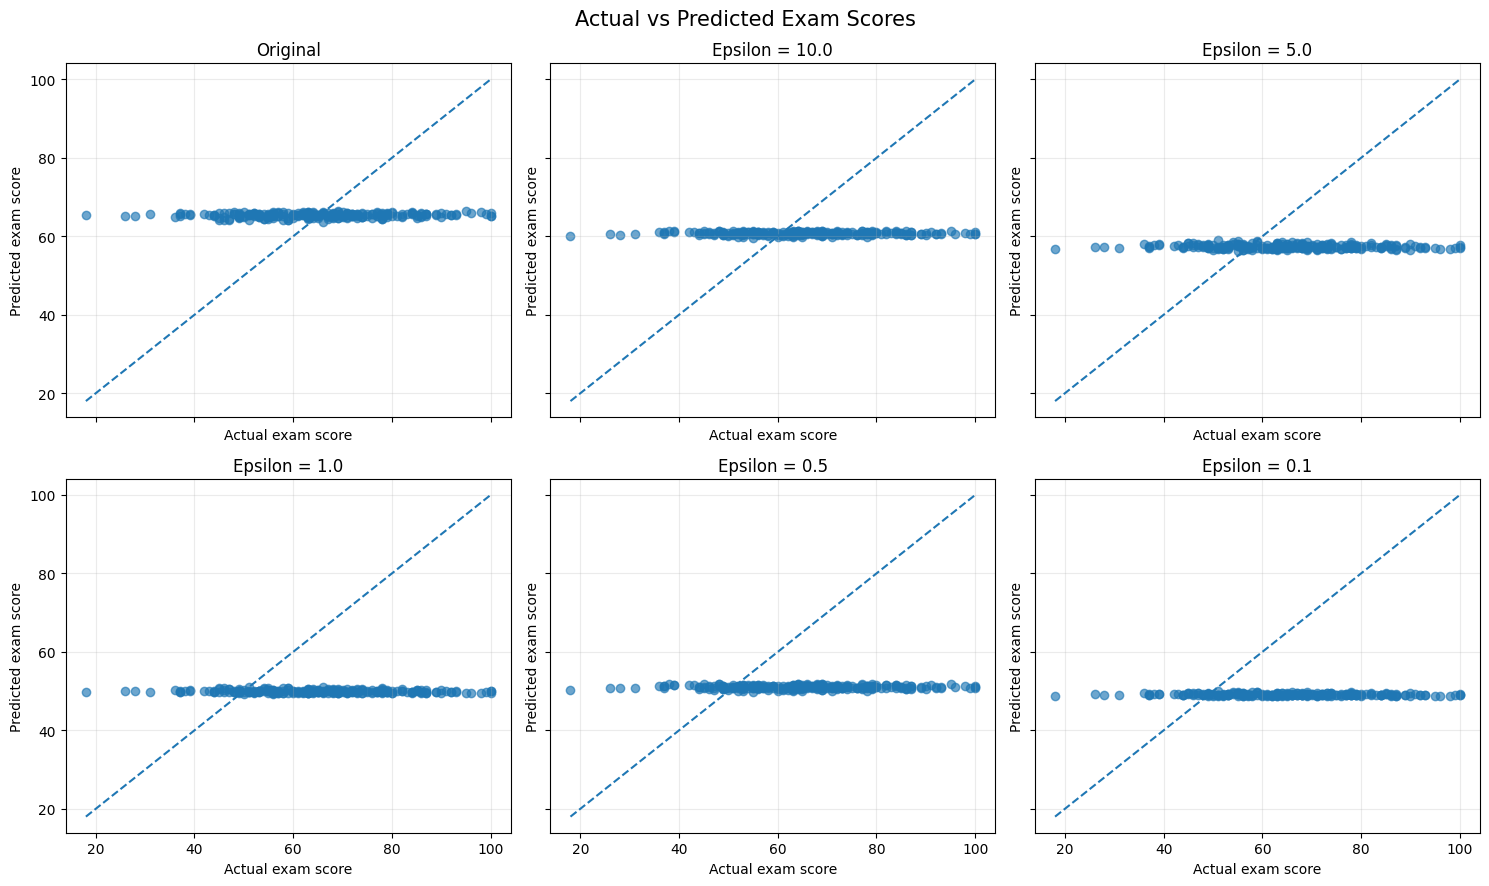

In [28]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9), sharex=True, sharey=True)
plot_models = [("Original", baseline_predictions)] + [
    (f"Epsilon = {eps}", ml_predictions[eps]) for eps in ML_EPSILONS
]
minimum = min(float(y_test_clean.min()), float(np.min(baseline_predictions)))
maximum = max(float(y_test_clean.max()), float(np.max(baseline_predictions)))
line = np.linspace(minimum, maximum, 100)

for ax, (label, predictions) in zip(axes.flat, plot_models):
    ax.scatter(y_test_clean, predictions, alpha=0.65)
    ax.plot(line, line, linestyle="--")
    ax.set_title(label)
    ax.set_xlabel("Actual exam score")
    ax.set_ylabel("Predicted exam score")
    ax.grid(alpha=0.25)

plt.suptitle("Actual vs Predicted Exam Scores", fontsize=15)
plt.tight_layout()
plt.show()

### 27.8 Compare R² and MAE across privacy budgets

R² is generally better when higher. MAE is the average absolute prediction error in exam-score points, so lower is better. The dashed line is the original-data baseline.

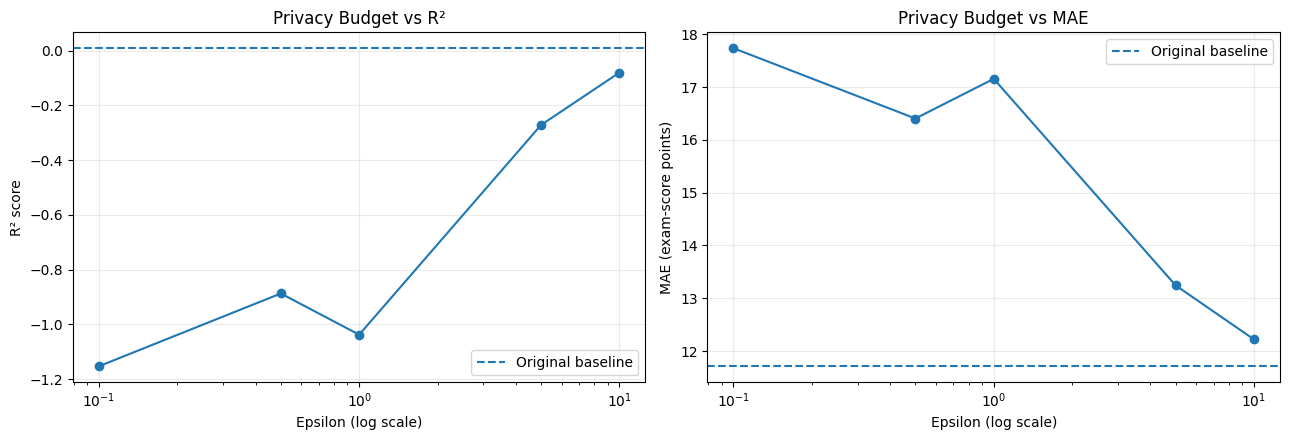

In [29]:
private_results_df = pd.DataFrame(ml_results).sort_values("Epsilon")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(private_results_df["Epsilon"], private_results_df["R2"], marker="o")
axes[0].axhline(baseline_metrics["R2"], linestyle="--", label="Original baseline")
axes[0].set_xscale("log")
axes[0].set_xlabel("Epsilon (log scale)")
axes[0].set_ylabel("R² score")
axes[0].set_title("Privacy Budget vs R²")
axes[0].legend()
axes[0].grid(alpha=0.25)

axes[1].plot(private_results_df["Epsilon"], private_results_df["MAE"], marker="o")
axes[1].axhline(baseline_metrics["MAE"], linestyle="--", label="Original baseline")
axes[1].set_xscale("log")
axes[1].set_xlabel("Epsilon (log scale)")
axes[1].set_ylabel("MAE (exam-score points)")
axes[1].set_title("Privacy Budget vs MAE")
axes[1].legend()
axes[1].grid(alpha=0.25)
plt.tight_layout()
plt.show()

### 27.9 Privacy–utility trade-off

We use test MAE as a utility measure. The chart compares the prediction error at each privacy budget with the original-data baseline.

Interpret the measured results rather than assuming the curve must be smooth or monotonic. Random noise, clipping, and this synthetic dataset can cause variation between privacy levels.

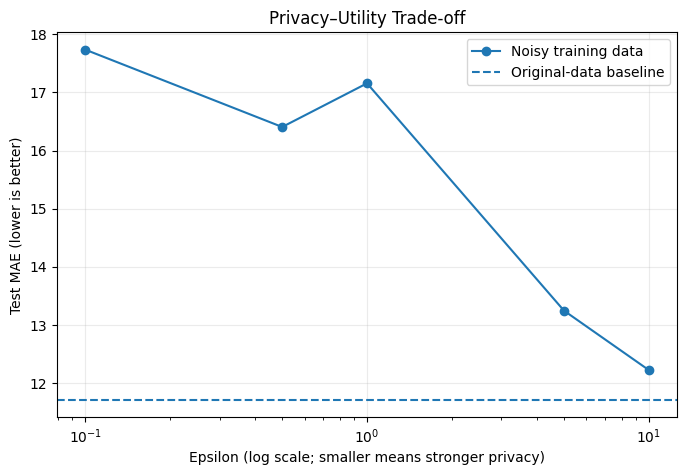

In [30]:
plt.figure(figsize=(8, 5))
plt.plot(private_results_df["Epsilon"], private_results_df["MAE"],
         marker="o", label="Noisy training data")
plt.axhline(baseline_metrics["MAE"], linestyle="--",
            label="Original-data baseline")
plt.xscale("log")
plt.xlabel("Epsilon (log scale; smaller means stronger privacy)")
plt.ylabel("Test MAE (lower is better)")
plt.title("Privacy–Utility Trade-off")
plt.grid(alpha=0.25)
plt.legend()
plt.show()

### 27.10 Interpretation of the ML experiment

Use your actual results to answer:

1. Which ε produced the closest R² and MAE to the original-data baseline?
2. At which ε values did prediction quality noticeably decrease?
3. Did stronger privacy generally require more noise?
4. Did any result depart from the expected trend? Consider sampling variation, clipping, and model sensitivity.
5. Are predictions still useful for this educational example?

Do not claim that the model is "almost identical" unless the measured metrics and prediction plots support that conclusion. Similar predictive performance does not prove that all privacy risks have been eliminated.

### 27.11 What CSPRNG contributes—and what it does not

- **CSPRNG:** makes the random noise harder to predict.
- **Differential Privacy:** the calibrated noise distribution, sensitivity, and privacy-budget accounting provide the mathematical privacy bound under the stated assumptions.
- **Machine Learning:** tests whether predictive utility is retained after training on perturbed records.

CSPRNG does not itself provide DP, reduce ε, or improve accuracy. With the same ideal noise distribution and scale, PRNG and CSPRNG should have the same expected statistical utility; their security properties differ.

### 27.12 Limitations and responsible conclusion

- The dataset contains 1,000 fictional students; results are an educational demonstration, not evidence about real student populations.
- Bounds must be justified and selected without leaking private information.
- We assume fixed-size, replace-one-record adjacency and one row per person's complete record.
- The train/test split is based on indices and is independent of values. Only training records are perturbed.
- The clean test set is used for evaluation, not training. Publishing detailed metrics can itself reveal information in a real deployment.
- Clipping noisy values is post-processing and does not spend additional privacy budget, but it affects utility.
- The CSPRNG Laplace sampler uses floating-point exponential sampling. Production DP requires a vetted sampler with documented finite-precision guarantees.
- This is a private-data-release approach followed by ordinary model training. A separate advanced experiment could use DP-SGD, which adds noise to clipped gradients during training.

**Final research conclusion:** Use the actual R², MAE, MSE, RMSE, and prediction plots to report whether noisy-data models retained useful predictive performance. This experiment investigates the hypothesis; it does not assume the hypothesis is true.